# EE191 Exercise - Decision Trees

In this exercise, we will implement a decision tree from scratch. The dataset labeled "train" in the Excel file contains the data available for building the model, which is a subset of a larger dataset. The sheet labeled "test" represents completely unseen data that the model has not encountered during training. Here, we will apply the decision tree to a dataset of miRNA expression to predict the presence of nasopharyngeal carcinoma (NPC), taking into account the expression of EBV-related miRNAs. After training, we will evaluate the model on a separate test set to observe its predictions on unseen data.

The provided code is kept simple to focus on the core concepts of decision tree construction and impurity-based splitting. You are encouraged to explore and extend it for your own projects.

## 1. Warming Up!

Before you start coding, complete the warm-up exercise first. This will help you recall the process of creating a decision tree by hand. Also, make sure to study the handout thoroughly before doing anything else.

# Loading Libraries

Before proceeding with the exercise, we first load the libraries that will be used throughout this notebook. Libraries are collections of pre-written code that provide useful functions and tools for specific tasks, such as data processing, visualization, and machine learning. By using libraries, we can focus on solving the problem at hand without needing to implement every component from scratch!

In [910]:
import pandas as pd
import numpy as np
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

# Loading the Dataset

First, we load our dataset. This dataset presents quantitative expression levels of 10 Epstein–Barr virus (EBV)-encoded BART microRNAs for each sample, where each row corresponds to an individual and each column represents a specific miRNA. The “Tumour stage” column indicates whether the sample is from a healthy individual or a patient with nasopharyngeal carcinoma (NPC), including the cancer stage when applicable. The numerical values reflect the measured abundance of each miRNA, with higher values indicating greater expression. To interpret the dataset, each sample can be analyzed by comparing its miRNA expression profile across the listed markers and relating it to its corresponding clinical classification.

In [911]:
def load_data(file_path, sheet_number):
    '''
    This function loads the sample features and labels from a dataset.
    
    INPUT:
        file_path - Path to the dataset file.
        sheet_number - Name or index of the sheet to load (e.g., training or test set).
    
    OUTPUT:
        X (float64) - Feature matrix of the dataset. An N × m matrix, where N is the number of samples and m is the number of features.
        y (categorical) - Label vector. An N × 1 array containing the class label corresponding to each sample.
    '''
    
    # Read the sheet as a dataframe
    df = pd.read_excel(file_path, sheet_name=sheet_number); 
    
    # Split the loaded dataframe into feature and label based on the column number
    y = df.iloc[:, 1];      # label --> first col
    X = df.iloc[:, 2:];    # feature --> 2nd col and so on
    
    # Convert to numericals to avoid possible NaN errors.
    y = y.values;
    X = X.values;

    # Print a dataset summarry.
    print(f"Dataset successfully loaded.");

    return X, y;

In [912]:
# Load dataset
X_train, y_train = load_data("dataset.xlsx","train");

Dataset successfully loaded.


# Data Visualization

Prior to training, we will first visualize the dataset distribution using a scatter plot. Because the dataset contains 10 features, it cannot be directly represented in a 2D plane; therefore, we will reduce its dimensionality while preserving the variability among samples using Principal Component Analysis (PCA), a technique that will be covered in more detail later in the course. For now, the focus is on the distribution of the classes rather than the specific meaning of the axes. This visualization is intended to assess the degree of class overlap, helping to set expectations and, in practical machine learning workflows, support model selection decisions.

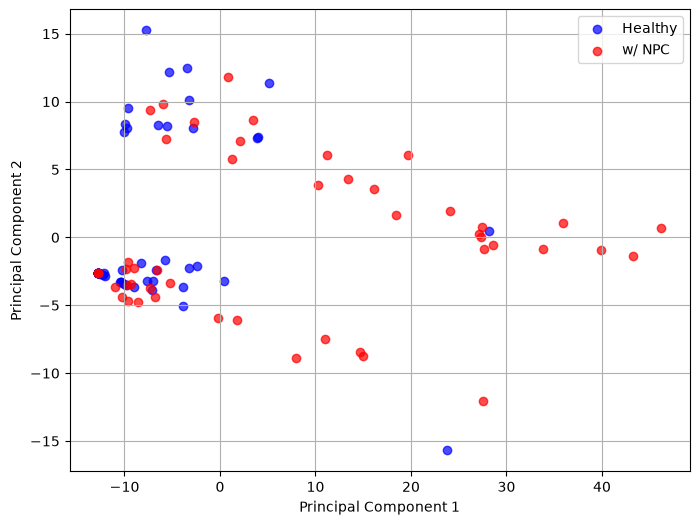

In [913]:
# Apply PCA (reduce to 2D)
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_train)

# Plot
plt.figure(figsize=(8, 6))

# Plot class 0 (blue)
plt.scatter(X_pca[y_train == 0, 0],X_pca[y_train == 0, 1],c='blue',label='Healthy',alpha=0.7)

# Plot class 1 (red)
plt.scatter(X_pca[y_train == 1, 0],X_pca[y_train == 1, 1],c='red',label='w/ NPC',alpha=0.7)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend()
plt.grid(True)

plt.show()

# Decision Tree Helper Functions

Now, we will begin implementing our decision tree from scratch. To simplify the process, we will break the algorithm down into modular components. Using these functions, we will then construct a class representing a decision tree node, allowing for a clean and concise implementation through a recursive approach.

In this part of the exercise, take your time to carefully read the description of each function and complete them step by step.

## 2. Determining Query Points

**Relevant functions**:

**set( )** – returns the unique values from a list, removing any duplicates.

**sorted( )** – arranges the values of a list in order from least to greatest.

In [914]:
def determine_query_points(X_f):
    '''
    Determines the query points of a dataset when a single feature is considered.

    INPUTS:
        X_f (float64) - An N × 1 vector containing the feature values for each of the N samples.

    OUTPUTS:
        query_points (float64) - An vector of floating point values which corresponds to the partition values.

    The query point partitions are computed as the midpoint between each unique value in X_f provided that 
    X_f is sorted from least to largest.
    '''

    #==================YOUR=CODE=HERE==========================
    query_points = [];
    
    # get unique values
    X_f = set(X_f);
    
    # sort X_f
    X_f = sorted(X_f);

    # get midpoints
    for k in range(len(X_f)-1):
        queryp = (X_f[k]+X_f[k+1])/2;
        query_points.append(queryp);

    query_points = sorted(list(set(query_points)));
    #==========================================================

    return query_points;

**Function-testing**

Often, when coding, it is important to run small experiments to verify that each function works correctly before proceeding to the next. This helps prevent errors from accumulating and becoming difficult to trace later on. In the code below, you are encouraged to test your function and validate its output by comparing it with a manual calculation.

In [915]:
# sample dataset (height measures of males (0) and females (1))
X_probe = [170, 165, 180, 182, 160, 155, 182, 158]
y_probe = [1,   0,   0,   0,   0,   1,   0,   1]

# determining query points
query_points = determine_query_points(X_probe);

# printing outputs
print(f"Query points: {query_points}")

Query points: [156.5, 159.0, 162.5, 167.5, 175.0, 181.0]


## 3. Computing Impurities

In [916]:
def compute_bernoulli_impurity(y, side=0):
    '''
    Computes for the impurity of a dataset using Bernoulli's formula

    INPUTS:
        y (categorical) - label of samples in the left or right side of the partition
        side ({1,0}) - left (0) or right (1) side of the partition.

    OUTPUTS:
        impurity (float64) - impurity measure a dataset's subset.
    '''
    
    #==================YOUR=CODE=HERE==========================

    # Create a list of all 0s or all 1s depending on the side.
    y_side = [];
    for k in range(len(y)):
        if y[k] == side:
            y_side.append(y[k]);

    # compare sample labels to partition side label (y_side)
    impurity = len(y)*((len(y_side))/len(y))*(1-(len(y_side))/len(y));

     #==========================================================
    
    return impurity;

In [917]:
# sample dataset (height measures of males (0) and females (1))
X_probe = [170, 165, 180, 182, 160, 155, 182, 158]
y_probe = [1,   0,   0,   0,   0,   1,   0,   1]

# test impurity assuming left side (0)
impurity_left = compute_bernoulli_impurity(y_probe, side=0)

# test impurity assuming right side (1)
impurity_right = compute_bernoulli_impurity(y_probe, side=1)

# printing outputs
print(f"Impurity (side = 0): {impurity_left}")
print(f"Impurity (side = 1): {impurity_right}")

Impurity (side = 0): 1.875
Impurity (side = 1): 1.875


## 4. Computing Side-wise Impurities

In [918]:
def compute_total_impurity(X_f, y, query_point):
    '''
    Computes the total impurity of a dataset when split on a single feature at a specified query point.
    
    INPUTS:
        X_f (float64) - An N × 1 vector containing the feature values for each of the N samples.
        y (categorical) - An N × 1 vector containing the labels corresponding to the N samples.
        query_point (float64) - The threshold value used to partition the dataset.
    
    OUTPUTS:
        left_impurity (float64) - The impurity of the subset of samples with feature values less than or equal to the query point.
        right_impurity (float64) - The impurity of the subset of samples with feature values greater than the query point.
    
    First, we sort X_f so as to arrange this from smallest to largest value.
    Second, we identify the labels of the samples from the left and right side of the query point.
    Lastly, we compute their corresponding impurity using the function we just written.
    '''
    # sort y according to X_f values
    X_f, y = zip(*sorted(zip(X_f,y)));
    
    #==================YOUR=CODE=HERE==========================
    
    # left-side labels
    y_left = [];

    # right-side labels
    y_right = [];

    for k in range(len(X_f)):
        if X_f[k] > query_point:
            y_right.append(y[k]);
        else:
            y_left.append(y[k]);
    
    #==========================================================
    
    # compute left-side query impurity
    left_impurity = compute_bernoulli_impurity(y_left,0);
    
    # compute right-side query impurity
    right_impurity = compute_bernoulli_impurity(y_right,1);
    
    return left_impurity, right_impurity;


In [919]:
# sample dataset (height measures of males (0) and females (1))
X_probe = [170, 165, 180, 182, 160, 155, 182, 158]
y_probe = [1,   0,   0,   0,   0,   1,   0,   1]
query_point = 162.5;

# left and right impurities
left_impurity, right_impurity = compute_total_impurity(X_probe, y_probe, query_point)

# printing outputs
print(f"Impurity (side = 0): {left_impurity}")
print(f"Impurity (side = 1): {right_impurity}")

Impurity (side = 0): 0.6666666666666667
Impurity (side = 1): 0.8


## 5. Dataset Partitioning

In [920]:
def partition_dataset(X_subset, y_subset, query_feature, query_point):
    '''
    This function partitions a dataset into two subsets using a specified feature and a
    corresponding query point.
    
    INPUTS:
        X_subset (float64) - An N × m array containing the feature values for N samples across m features.
        y_subset (categorical) - An N × 1 vector containing the labels corresponding to the samples in X_subset.
        query_feature (int) - The index of the feature used to perform the partition.
        query_point (float64) - The threshold value used to split the dataset.
    
    OUTPUTS:
        X_left (float64) - An N_left × m array containing the samples whose feature values are less than or equal to the query point.
        y_left (categorical) - An N_left × 1 vector containing the labels corresponding to the samples in X_left.
        X_right (float64) - An N_right × m array containing the samples whose feature values are greater than the query point.
        y_right (categorical) - An N_right × 1 vector containing the labels corresponding to the samples in X_right.
    
    '''
    
    n_left = [n for n, x in enumerate(X_subset) if x[query_feature]<query_point];
    n_right = [n for n, x in enumerate(X_subset) if x[query_feature]>query_point];

    #-----------FIX 1---------------
    #X_subset = np.array[X_subset];
    #y_subset = np.array[y_subset];
    
    #X_left = X_subset[n_left];
    #y_left = y_subset[n_left];
    
    #X_right = X_subset[n_right];
    #y_right = y_subset[n_right];
    #-----------FIX 1---------------
    
    X_left = [];
    y_left = [];
    for k in range(len(n_left)):
        X_left.append(X_subset[n_left[k]]);
        y_left.append(y_subset[n_left[k]]);
    
    X_right = [];
    y_right = [];
    for k in range(len(n_right)):
        X_right.append(X_subset[n_right[k]]);
        y_right.append(y_subset[n_right[k]]);

    return X_left, X_right, y_left, y_right;

In [921]:
# sample dataset (individual data of males (0) and females (1)).
# 1st column - height
# 2nd column - weight
# 3rd column - IQ
X_probe = np.array([
    [170, 70, 105],
    [165, 60, 110],
    [180, 80, 100],
    [182, 85, 98],
    [160, 55, 115],
    [155, 50, 120],
    [182, 78, 102],
    [158, 52, 118]
])

y_probe = [1, 0, 0, 0, 0, 1, 0, 1]

# query point vector
query_point = [162.5, 71, 112]

# feature to query and separate. Change this depending on the feature you want to query.
n_feature = 2
X_left, X_right, y_left, y_right = partition_dataset(X_probe, y_probe, n_feature, query_point[n_feature])

print("Query point: ", query_point[n_feature]);

print("X_left:\n", X_left)
print("y_left:", y_left)

print("\nX_right:\n", X_right)
print("y_right:", y_right)

Query point:  112
X_left:
 [array([170,  70, 105]), array([165,  60, 110]), array([180,  80, 100]), array([182,  85,  98]), array([182,  78, 102])]
y_left: [1, 0, 0, 0, 0]

X_right:
 [array([160,  55, 115]), array([155,  50, 120]), array([158,  52, 118])]
y_right: [0, 1, 1]


# 6. Training Decision Trees

Now, we will combine everything to implement the decision tree. You won’t need to write any additional code here, but you are encouraged to carefully read and understand how the implementation works.

In [922]:
def determine_best_query(X_subset, y_subset):
    '''
    This determines the best query for a given dataset. Produces a node in the process.

    INPUTS:
        X_subset (float64) - Feature matrix of the dataset. An N × m matrix, where N is the number of samples and m is the number of features.
        y_subset (categorical) - Label vector. An N × 1 array containing the class label corresponding to each sample.

    OUTPUTS:
        query_feature (int) - The index of the feature used to perform the partition.
        query_point (float64) - The threshold value used to split the dataset.
        left_impurity (float64) - The impurity of the subset of samples with feature values less than or equal to the query point.
        right_impurity (float64) - The impurity of the subset of samples with feature values greater than the query point.
         X_left (float64) - An N_left × m array containing the samples whose feature values are less than or equal to the query point.
        y_left (categorical) - An N_left × 1 vector containing the labels corresponding to the samples in X_left.
        X_right (float64) - An N_right × m array containing the samples whose feature values are greater than the query point.
        y_right (categorical) - An N_right × 1 vector containing the labels corresponding to the samples in X_right.

    '''
    # number of features in X;
    m = len(X_subset[0]);
    
    # computing feature impurity per feature per query point
    feature_impurity = [None]*m;               #creates feature_impurity array containg an m number of elements designated a value of None.
    feature_query_point = [None]*m;            #same as feature_impurity.

    # For-LOOP for each feature
    for i in range(m):

        # determine query points for feature m
        query_points = determine_query_points(X_subset[:,i])            

        # initialize the impurity of feature m to infinity.
        
        feature_impurity[i] = float('inf');          #inf is chosen so that regardless of the value, the first impurity to be solved will
                                                     #be the default best impurity.

        # For-LOOP for each query points
        for query_point in query_points:

            # compute for left and right impurity for a given query point for a given feature
            left_impurity, right_impurity = compute_total_impurity(X_subset[:,i], y_subset, query_point);

            # compute total impurity for a given query point for a given feature
            impurity = left_impurity + right_impurity;

            # if computed query impurity is smaller than previous, override impurity measure and query point
            if feature_impurity[i]>impurity:
                feature_impurity[i] = impurity;
                feature_query_point[i] = query_point;          #the query point that maximizes delta_L (the query point that minimizes impurity)
                                                               #for each feature m is evaluated.

    # determining best feature and query point by arranging the impurities from least to greatest. 
    feature_impurity, feature_query_point, n_feature  = zip(*sorted(zip(feature_impurity,feature_query_point, list(range(m)))));
    query_feature = n_feature[0]; 
    query_point =  feature_query_point[0];
    
    # recomputing impurities to determine left and right impurities. We will need these to determine when to create a leaf.
    left_impurity, right_impurity = compute_total_impurity(X_subset[:,query_feature], y_subset, query_point);

    # partition dataset
    X_left, X_right, y_left, y_right = partition_dataset(X_subset, y_subset, query_feature, query_point);

    return query_feature, query_point, left_impurity, right_impurity, X_left, X_right, y_left, y_right;

In [923]:
class tree_node:
    '''
    This object represents a node in a decision tree used for binary classification.

    This class recursively constructs the decision tree by selecting the best feature and query point 
    (threshold) to split the dataset at each node. Each node stores the feature and threshold used for 
    the split, along with references to its left and right children.

    The recursive structure allows the tree to be built in a concise and readable way: each node simply 
    creates its child nodes using smaller subsets of the data until a stopping condition is reached.

    Recursion terminates when either:
    1. All samples in the current subset belong to the same class, or
    2. The maximum tree depth is reached.

    The `max_depth` parameter acts as a regularization mechanism to limit the complexity of the tree 
    and reduce overfitting. By restricting how deep the tree can grow, the model avoids fitting noise 
    in the training data.

    Leaf nodes store the majority class label of the samples in the subset, which is used during prediction.

    PROPERTIES:
    query_feature (int) - The index of the feature used to perform the partition.
    query_point (float64) - The threshold value used to split the dataset.
    left_child - a leaf ({1,0}) or a node (another tree_node object).
    right_child - a leaf ({1,0}) or a node (another tree_node object).
    '''
    qpoint_train=[];
    qfeat_train=[];
    X_left_col = [];
    X_right_col = [];
    
    def __init__(self, X_subset, y_subset, depth=0, max_depth=10):
        '''
        Initializes the object

        INPUT:
            X_subset (float64) - Feature matrix of the dataset. An N × m matrix, where N is the number of samples and m is the number of features.
            y_subset (categorical) - Label vector. An N × 1 array containing the class label corresponding to each sample.
            depth (int) - depth in which the tree_node object belongs.
            max_depth (int) - maximum depth for the model
        '''
        
        
        # Stop if all labels are the same or max depth is reached
        if len(set(y_subset)) == 1 or depth >= max_depth:                 #set() removes duplicates of label values in dataset inputted.
                                                                          #Since duplicates are removed, unique values are identified and are 
                                                                          #counted by len(). A single unique value implies that impurity is zero,
                                                                          #and thus requires no further querying. Thus the if statement assesses
                                                                          #whether that condition or if depth has reached its max allowed is met.
            # Leaf label: majority class; the label is the majority class
            self.left_child = self.right_child = 1 if sum(y_subset) > len(y_subset)/2 else 0            #this creates a leaf node. Since there is no
                                                                                                        #need for querying, the children of this node
                                                                                                        #are given the same labels. (Everyone's label
                                                                                                        #is the same, so even if you split the group,
                                                                                                        #label is still the same for them)
            # no need to initialize partition properties                 #no need since it's a leaf node.
            self.query_feature = None
            self.query_point = None
            
            return
        
        # Determine best split using the dataset S{X_subset, y_subset}
        query_feature, query_point, imp_left, imp_right, X_left, X_right, y_left, y_right = determine_best_query(X_subset, y_subset)
        X_left = np.array(X_left)
        X_right = np.array(X_right)
        y_left = np.array(y_left)
        y_right = np.array(y_right)
        tree_node.qpoint_train.append(query_point);
        tree_node.qfeat_train.append(query_feature);
        tree_node.X_left_col.append(X_left);
        tree_node.X_right_col.append(X_right);
        
        # initializes partition properties
        self.query_feature = query_feature
        self.query_point = query_point

        # Left child decision
        if imp_left == 0 or len(set(X_left[:, query_feature])) == 1: # create a leaft if partition yields polarized set
            self.left_child = 1 if sum(y_left) > len(y_left)/2 else 0
        else:
            # increment tree node depth and create another object
            self.left_child = tree_node(X_left, y_left, depth=depth+1, max_depth=max_depth)

        # Right child decision
        if imp_right == 1 or len(set(X_right[:, query_feature])) == 1: # create a leaft if partition yields polarized set
            self.right_child = 1 if sum(y_right) > len(y_right)/2 else 0
        else:
            # increment tree node depth and create another object
            self.right_child = tree_node(X_right, y_right, depth=depth+1, max_depth=max_depth)

In [924]:
def predict_sample(model, x):
    '''
    This function predicts the class label for a single sample using a trained decision tree model.
    
    INPUTS:
        model (object) - A decision tree model.
        x (float64) - A 1 × m vector containing the feature values for a single sample.
    
    OUTPUT:
        label (categorical) - A binary class label (0 or 1) predicted by the model.
    '''
    
    # If model is numeric, it means that it is a leaf node. 
    if isinstance(model, int):
        label = model;
        return label;

    # Node with no query is also a leaf. 
    if model.query_feature is None or model.query_point is None:
        if isinstance(model.left_child, int):
            label = model.left_child;
        else:
            label = model.right_child;
        return label;

    # Branching with queries result to tree objects
    if x[model.query_feature] <= model.query_point:
        label = predict_sample(model.left_child, x)
    else:
        label = predict_sample(model.right_child, x);

    return label;

## Model-training

In [925]:
# training a model with a max depth of 5
model = tree_node(X_train, y_train, max_depth = 7)

# vector to store the labels as classified by the model.
label_train = [];

for i in range(len(y_train)):

    # predict samples one by one.
    output = predict_sample(model, X_train[i,:]);

    # if X_train[i,0] > 6.10739841316485:
    #     if X_train[i,4]>0.2154352968703555:
    #         output = 1;
    #     else:
    #         output = 0;
    # else:
    #     if X_train[i,8]>3.133106473509385:
    #         output = 1;
    #     else:
    #         output = 0;
    label_train.append(output);

print(f"Number of Left Branches: ",len( model.X_left_col));
print(f"Number of Right Branches: ",len( model.X_right_col));
print(f"Model qfeat:",model.qfeat_train);
print(f"Model qpoint:",model.qpoint_train);
print(f"Training labels (", len(label_train), "): ", label_train);

Number of Left Branches:  4
Number of Right Branches:  4
Model qfeat: [0, 8, 7, 4]
Model qpoint: [np.float64(6.10739841316485), np.float64(3.133106473509385), np.float64(5.54372638912555), np.float64(0.2154352968703555)]
Training labels ( 100 ):  [0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 1, 0, 1, 0, 0, 0, 1, 0, 0, 1, 0, 1, 0, 1, 1, 1, 0, 0, 1, 1, 0, 1, 0, 1, 1, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]


In [926]:
def compute_accuracy(y, label_true):
    '''
    This function computes for the accuracy of a model

    INPUTS:
    y (categorical) - Label vector. An N × 1 array containing the class label assigned by the model per sample.
    label_true (categorical) - Label vector. An N × 1 array containing the true class label corresponding to each sample.

    OUTPUT:
    acc (float64) - a single value corresponding to the accuracy.
    
    '''

    # variable to count number of correct guesses
    correct = 0;

    # total number of samples
    N = len(y);

    # counting number of correct guesses
    for i in range(N):
        if y[i] == label_true[i]:
            correct = correct + 1;

    # compute accuracy
    acc = correct/N;
    
    return acc

In [927]:
# compute and display model accuracy accross the training set

acc = compute_accuracy(label_train, y_train);
print(f"Training accuracy: {acc*100: .2f}%")

Training accuracy:  79.00%


# 7. Decision Trees Evaluation

Finally, we will evaluate our model using an external dataset that does not include any labels. Although we cannot compute accuracy or formally validate our results in this case, in typical scientific practice, model predictions are verified against a standard diagnostic method for detecting or ruling out an event, often referred to as a “gold standard.”

In [928]:
# loading test dataset
X_test, y_test = load_data("dataset.xlsx","test");

Dataset successfully loaded.


In [929]:
label_test = [];

for i in range(len(X_test)):
    output = predict_sample(model, X_test[i,:]);
    label_test.append(output);

print(label_test)

[0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 0, 1, 0, 1]
